#Experiment 3: Breadth-first and depth-first search

In [ ]:
import numpy as np
from collections import deque

# 1 = wall, 0 = open
maze = np.array([
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    [1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1],
    [1,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1],
    [1,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1],
    [1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,0,1,0,1],
    [1,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1],
    [1,0,1,0,1,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1],
    [1,0,1,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,1],
    [1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1],
    [1,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1],
    [1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1],
    [1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1],
    [1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1],
    [1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1],
    [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]
])

H, W = maze.shape
START, GOAL = (1, 1), (H-2, W-2)

def neighbours(cell):
    r, c = cell

    for dr, dc in ((-1,0), (1,0), (0,-1), (0,1)):
        nr, nc = r + dr, c + dc

        if 0 <= nr < H and 0 <= nc < W:
            if maze[nr, nc] == 0:
                yield (nr, nc)

In [ ]:
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}  # doubles as the explored set
    order = {}              # cell -> the step at which it was expanded

    while frontier:
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()

        # <-- THE ONLY DIFFERENCE BETWEEN THE TWO ALGORITHMS
        if node in order:
            continue

        order[node] = len(order)

        if node == goal:
            break

        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)

    path, cur = [], goal

    if goal in parent:
        while cur is not None:
            path.append(cur)
            cur = parent[cur]

    return order, path[::-1]


for mode in ('bfs', 'dfs'):
    order, path = search(START, GOAL, mode)
    print(f'{mode.upper()}: {len(order)} expanded, path length {len(path)}')

BFS: 137 expanded, path length 95
DFS: 105 expanded, path length 95


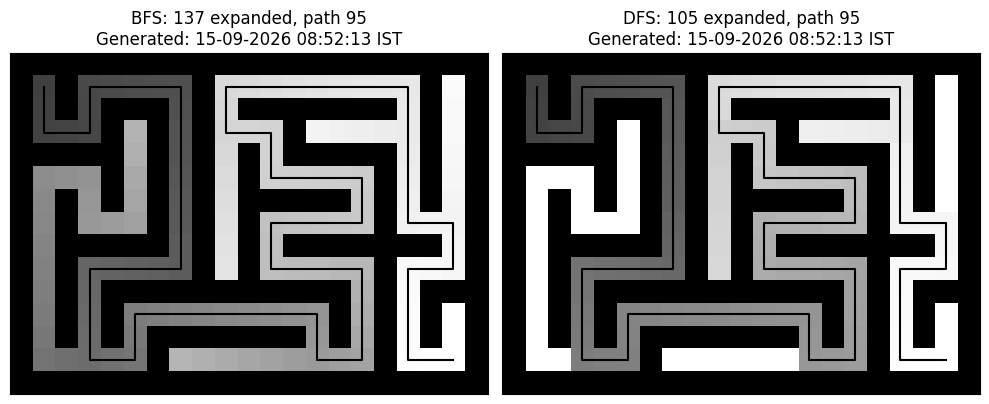

In [ ]:
import matplotlib.pyplot as plt
from datetime import datetime
from zoneinfo import ZoneInfo

# Get current date and time in Indian Standard Time
current_datetime = datetime.now(
        ZoneInfo("Asia/Kolkata")
    ).strftime("%d-%m-%Y %H:%M:%S IST")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, mode in zip(axes, ['bfs', 'dfs']):
    order, path = search(START, GOAL, mode)

    grid = np.full(maze.shape, np.nan)  # nan = never expanded

    for (r, c), k in order.items():
        grid[r, c] = k  # shade by expansion order

    ax.imshow(maze, cmap='binary')
    ax.imshow(grid, cmap='Greys_r', alpha=0.75)

    ax.plot(
        [c for _, c in path],
        [r for r, _ in path],
        lw=1.5,
        color='k'
    )

    ax.set_title(
    f'{mode.upper()}: {len(order)} expanded, path {len(path)}\n'
    f'Generated: {current_datetime}'
)

    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()